In [1]:
#!/usr/bin/env python3
"""
==============================================================================
VISUAL VALIDATION OF THE RADAR RESULTS  (haor_visual_validation.ipynb)
==============================================================================
Written after the 1 October meeting with Prof. Yamazaki and the assistant
professor. Their shared point: every connectivity and timing result so far was
shown as numbers and curves, never as the actual maps. "Doubt your result, even
the methodology." This notebook draws, from the real data, what each result
claims, so it can be judged by eye and by an independent reference.

CELL MAP (each cell names the meeting comment it answers)
  V1   pick the key dates: before / at / after merging, peak, 2022 event
       -> writes validation/key_dates.csv for haor_export_validation_images.py
  V2   what the algorithm saw on those dates: observed, filled, removed, bodies
  V3   time-lapse of every season (GIF and MP4), labelled connected / not
  V4   WHERE the connections cross: boundary crossing maps and statistics
  V5   real Sentinel-1 backscatter and Sentinel-2 images on the key dates,
       plus the 20 m flood flag checked against the 100 m result
  V6   onset and recession as 2D maps (RQ1 was never shown as maps)
  V6b  RQ1: the recession spread against the right yardsticks
  V7   2022: the flash flood used as the case study
  V8   blind reference set: label image cards by eye, without the algorithm
  V9   agreement between your eye labels and the algorithm
  V10  100 m against 30 m: does connectivity survive finer pixels?
  V11  parameter sensitivity, from haor_parameter_sensitivity.py
  V12  statistics without pseudo-replication, and the hysteresis gap with an interval
  V13  the scorecard: every check, pass / fail / pending

RUN ORDER
  1. python haor_validation_labels.py        (server, once)
  2. this notebook, V1 to V4, V6, V7, V11, V12
  3. python haor_export_validation_images.py (server) -> Drive -> download
  4. this notebook, V5, V8; label the cards by hand; V9
  5. hi-res export + labels --res 30 -> V10
==============================================================================
"""
import os, sys, re, glob, json, shutil, datetime, subprocess
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
import rasterio
from rasterio.plot import plotting_extent
from scipy import ndimage
from scipy.stats import mannwhitneyu
print("✓ imports ok")

✓ imports ok


In [2]:
# ============================ PATHS & SETTINGS ============================
CODE_DIR      = "/work/a06/wasif"                       # where haor_validation_core.py lives
BASE          = "/work/a06/wasif/haor_flood_analysis_hydroyear"
ANALYSIS_ROOT = os.path.join(BASE, "analysis")
VAL           = os.path.join(ANALYSIS_ROOT, "validation")
LABELS        = os.path.join(VAL, "labels")
IMAGES        = os.path.join(VAL, "images")
FIGS          = os.path.join(VAL, "figs")
HAORS_SHP     = "/work/a06/wasif/haor_flood_analysis/digitization/haors_manual.shp"
JRC_TIF       = "/work/a06/wasif/haor_flood_analysis/haor_digitization_tanguar/tanguar_jrc_occurrence.tif"
SWOT_PERHAOR  = "/work/a06/wasif/haor_flood_analysis_multiyear/analysis/swot_perhaor_wse.csv"
os.makedirs(FIGS, exist_ok=True)
sys.path.insert(0, CODE_DIR)
import haor_validation_core as core

MATCH_DAYS   = 3          # SWOT pass counts as matched within this many days
WATER_DB     = -13.0      # permanent water, identical to the main notebook
PERM_JRC     = 75
HAOR_COLORS  = {"GMA": "#E07856", "TGR": "#1C7293", "HLR": "#0F766E", "SHN": "#7C3AED", "MTN": "#0A2540"}
BODY_COLORS  = ["#1C7293", "#E07856", "#7C3AED", "#0F766E", "#B45309", "#DB2777", "#65A30D", "#0A2540"]
CENTRAL      = "GMA"

YEARS = sorted(int(re.search(r"(\d{4})", os.path.basename(f)).group(1))
               for f in glob.glob(os.path.join(BASE, "flood_stack_cluster_*.tif")))
os.environ["SHAPE_RESTORE_SHX"] = "YES"
haors = gpd.read_file(HAORS_SHP)
haors = haors[haors["haor_id"] != "DUMMY"].copy()
if (~haors.geometry.is_valid).any():
    haors["geometry"] = haors.geometry.buffer(0)
HAOR_IDS = haors["haor_id"].tolist()

conn, mats, curves, timing = {}, {}, {}, {}
for y in YEARS:
    d = os.path.join(ANALYSIS_ROOT, str(y))
    conn[y]   = pd.read_csv(os.path.join(d, f"connectivity_curve_{y}.csv"))
    mats[y]   = pd.read_csv(os.path.join(d, f"haor_connection_matrix_{y}.csv"))
    curves[y] = pd.read_csv(os.path.join(d, f"haor_hydrograph_curves_{y}.csv"))
    curves[y]["cluster_frac"] = curves[y][HAOR_IDS].mean(axis=1)
    timing[y] = pd.read_csv(os.path.join(d, f"haor_hydrograph_timing_{y}.csv"))
summary = pd.read_csv(os.path.join(ANALYSIS_ROOT, "multiyear_summary.csv")).set_index("year")
adj = pd.read_csv(os.path.join(VAL, "adjacency.csv")) if os.path.exists(os.path.join(VAL, "adjacency.csv")) \
      else core.adjacency(haors)
ADJ = adj.loc[adj.adjacent, "pair"].tolist()
swot_dates = []
if os.path.exists(SWOT_PERHAOR):
    swot_dates = sorted(pd.to_datetime(pd.read_csv(SWOT_PERHAOR)["dt"]).dt.date.unique())
have_labels = all(os.path.exists(os.path.join(LABELS, f"labels_{y}.tif")) for y in YEARS)
print("years:", YEARS, "| haors:", HAOR_IDS)
print("adjacent pairs:", ADJ)
print(f"SWOT dates available: {len(swot_dates)}")
print("label rasters:", "found" if have_labels else "MISSING, run python haor_validation_labels.py first")

years: [2019, 2020, 2021, 2022, 2023, 2024, 2025] | haors: ['MTN', 'SHN', 'HLR', 'TGR', 'GMA']
adjacent pairs: ['SHN-GMA', 'HLR-GMA']
SWOT dates available: 159
label rasters: found


In [3]:
# ============================ HELPERS ============================
def band_index(path, year):
    """{day index: band number} for any of our multi-band rasters."""
    with rasterio.open(path) as s:
        return {core.dayidx(d, year): i + 1 for i, d in enumerate(s.descriptions)}

def read_band(path, year, doy):
    idx = band_index(path, year)
    k = min(idx, key=lambda d: abs(d - doy))
    if abs(k - doy) > 0.5:
        raise KeyError(f"no band for day {doy} in {os.path.basename(path)}")
    with rasterio.open(path) as s:
        a = s.read(idx[k]); ext = plotting_extent(s); tr, crs = s.transform, s.crs
    return a, ext, tr, crs

def draw_haors(ax, lw=1.6, names=True, crs="EPSG:4326"):
    hv = haors.to_crs(crs)
    for _, h in hv.iterrows():
        gpd.GeoSeries([h.geometry.boundary], crs=crs).plot(ax=ax, color=HAOR_COLORS.get(h.haor_id, "k"), lw=lw, zorder=5)
        if names:
            p = h.geometry.representative_point()
            ax.annotate(h.haor_id, (p.x, p.y), ha="center", va="center", fontsize=8, fontweight="bold",
                        color=HAOR_COLORS.get(h.haor_id, "k"), zorder=6,
                        bbox=dict(boxstyle="round,pad=0.12", fc="white", alpha=.8, lw=0))
    ax.set_xlabel(""); ax.set_ylabel("")

CODE_CMAP = ListedColormap(["#FFFFFF", "#F4E9CD", "#1C7293", "#7FB8CC", "#E07856", "#E9E2CF", "#94A3B8"])
CODE_NORM = BoundaryNorm(np.arange(-0.5, 7.5, 1), CODE_CMAP.N)
CODE_LEGEND = [mpatches.Patch(color=CODE_CMAP(i), label=core.CODE_NAMES[i]) for i in range(1, 7)]

def body_rgb(lab):
    """Colour bodies by size rank so the same colour means 'largest body' on every map."""
    rgb = np.ones(lab.shape + (3,))
    ids, cnt = np.unique(lab[lab > 0], return_counts=True)
    for r, k in enumerate(ids[np.argsort(-cnt)]):
        c = BODY_COLORS[r] if r < len(BODY_COLORS) else "#9CA3AF"
        rgb[lab == k] = [int(c[i:i + 2], 16) / 255 for i in (1, 3, 5)]
    return rgb

def state_text(year, doy):
    m = mats[year].set_index("doy")
    k = m.index[np.argmin(np.abs(m.index - doy))]
    row = m.loc[k]
    if (row[HAOR_IDS] < 0).any():
        return "date skipped (coverage)", row
    n = core.doy_to_date(year, doy)
    deg = int(sum(row[h] == row[CENTRAL] and row[CENTRAL] > 0 for h in HAOR_IDS)) if row[CENTRAL] > 0 else 0
    nz = [row[h] for h in HAOR_IDS if row[h] > 0]
    allc = len(nz) == len(HAOR_IDS) and len(set(nz)) == 1
    return (f"ALL FIVE CONNECTED" if allc else f"{deg} of 5 share {CENTRAL}'s body"), row

def frac_at(year, doy):
    c = curves[year]
    return float(c.loc[(c["doy"] - doy).abs().idxmin(), "cluster_frac"])

def nearest_swot(date):
    if not swot_dates:
        return None
    s = min(swot_dates, key=lambda d: abs((d - date).days))
    return s if abs((s - date).days) <= MATCH_DAYS else None

def perm_mask_on(tr, shape, crs):
    """Permanent water exactly as cell 3 of the main notebook."""
    from rasterio.warp import reproject, Resampling
    out = np.zeros(shape, bool)
    for path, test in [(os.path.join(BASE, "baseline_mean_pooled.tif"), lambda a: a < WATER_DB),
                       (JRC_TIF, lambda a: a > PERM_JRC)]:
        if not os.path.exists(path):
            continue
        dst = np.full(shape, np.nan, "float32")
        with rasterio.open(path) as s:
            reproject(rasterio.band(s, 1), dst, src_transform=s.transform, src_crs=s.crs,
                      dst_transform=tr, dst_crs=crs, resampling=Resampling.bilinear)
        out |= np.isfinite(dst) & test(dst)
    return out
print("✓ helpers defined")

✓ helpers defined


In [4]:
# ============ V1: PICK THE KEY DATES ============
# Meeting: "You don't need to show all 365 days. Pick representative dates: when
# they start to merge, when they separate, and the peak." (Prof. Yamazaki), and
# "use 2022 as a validation period" (assistant professor).
# For every year: the last separate date before the FIRST merge of the season,
# that first merged date, the last merged date, the first separate date after
# it, and the date of peak flooded fraction. For 2022 also the April to June
# event window. Dates with a SWOT pass within 3 days are flagged, because those
# can be checked by both instruments.
rows = []
for y in YEARS:
    v = conn[y][conn[y]["n_components"] >= 0].sort_values("doy").reset_index(drop=True)
    ep = core.episodes(conn[y])
    def add(role, doy):
        d = core.doy_to_date(y, doy)
        st, row = state_text(y, doy)
        s = nearest_swot(d)
        rows.append(dict(label=f"{y}_{role}", year=y, doy=float(doy), date=d.isoformat(), role=role,
                         state=st, cluster_frac=round(frac_at(y, doy), 3),
                         swot_date=s.isoformat() if s else ""))
    if ep:
        first, last = ep[0], ep[-1]
        before = v[v.doy < first[0]]
        if len(before): add("firstmerge_pre", before.doy.iloc[-1])
        add("firstmerge_on", first[0])
        add("lastmerge_on", last[1])
        after = v[v.doy > last[1]]
        if len(after): add("lastmerge_post", after.doy.iloc[0])
        # in SWOT years, also the transition best covered by SWOT on both sides
        if y >= 2023 and swot_dates:
            best = None
            for s, e, n in ep:
                pre = v[v.doy < s].doy
                if not len(pre): continue
                a, b = core.doy_to_date(y, pre.iloc[-1]), core.doy_to_date(y, s)
                if nearest_swot(a) and nearest_swot(b) and nearest_swot(a) != nearest_swot(b):
                    best = (pre.iloc[-1], s); break
            if best:
                add("swotpair_pre", best[0]); add("swotpair_on", best[1])
    pk = curves[y].loc[curves[y]["cluster_frac"].idxmax(), "doy"]
    add("peak", pk)
    if y == 2022:
        for k, d in enumerate([100, 110, 120, 130, 145]):
            dd = v.doy.iloc[int(np.argmin(np.abs(v.doy - d)))]
            add(f"event{k+1}", dd)
KEY = pd.DataFrame(rows).drop_duplicates(subset=["year", "doy"]).reset_index(drop=True)
KEY.to_csv(os.path.join(VAL, "key_dates.csv"), index=False)
print(KEY.to_string(index=False))
print(f"\nwrote {os.path.join(VAL, 'key_dates.csv')}  ({len(KEY)} dates, "
      f"{(KEY.swot_date != '').sum()} with a SWOT pass within {MATCH_DAYS} days)")
print("NEXT on the server: python haor_export_validation_images.py")

              label  year   doy       date           role                   state  cluster_frac  swot_date
2019_firstmerge_pre  2019 158.0 2019-06-08 firstmerge_pre 4 of 5 share GMA's body         0.759           
 2019_firstmerge_on  2019 163.0 2019-06-13  firstmerge_on      ALL FIVE CONNECTED         0.824           
  2019_lastmerge_on  2019 307.0 2019-11-04   lastmerge_on      ALL FIVE CONNECTED         0.790           
2019_lastmerge_post  2019 309.0 2019-11-06 lastmerge_post 1 of 5 share GMA's body         0.576           
          2019_peak  2019 205.0 2019-07-25           peak      ALL FIVE CONNECTED         0.889           
2020_firstmerge_pre  2020 153.0 2020-06-02 firstmerge_pre 1 of 5 share GMA's body         0.441           
 2020_firstmerge_on  2020 158.0 2020-06-07  firstmerge_on      ALL FIVE CONNECTED         0.885           
  2020_lastmerge_on  2020 314.0 2020-11-10   lastmerge_on      ALL FIVE CONNECTED         0.791           
2020_lastmerge_post  2020 316.0 2020-

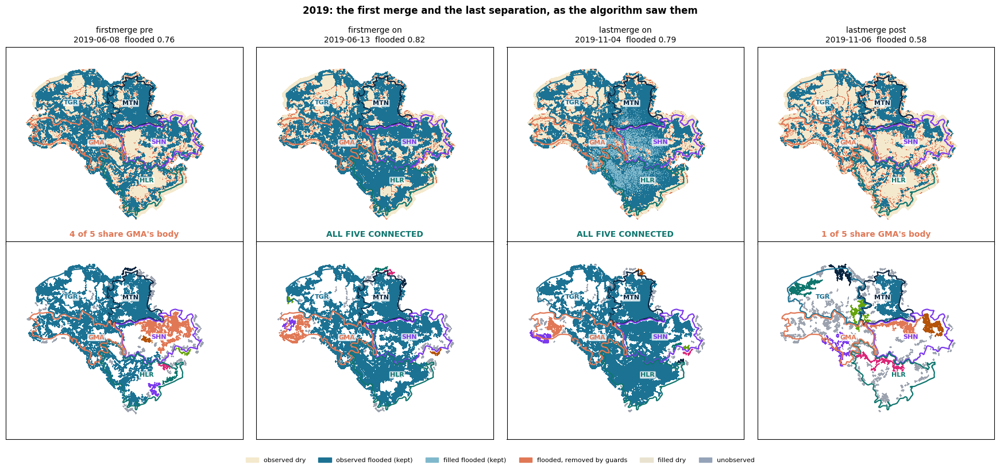

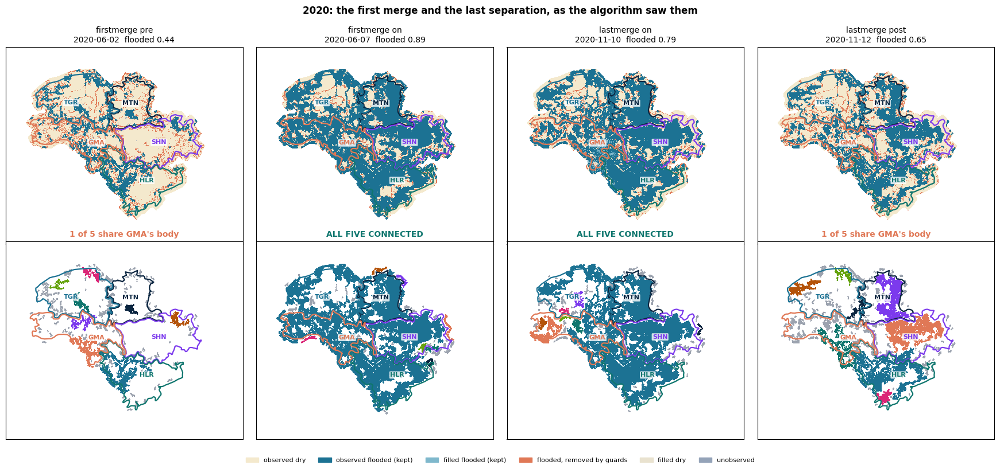

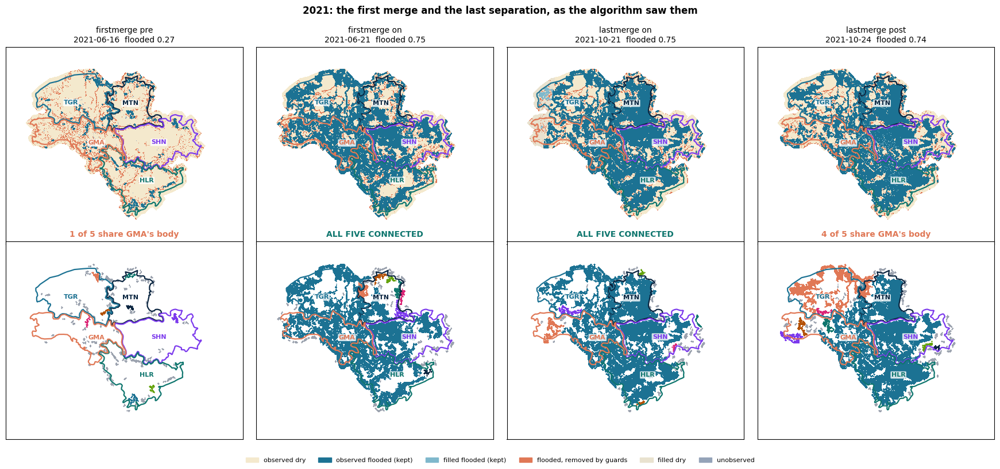

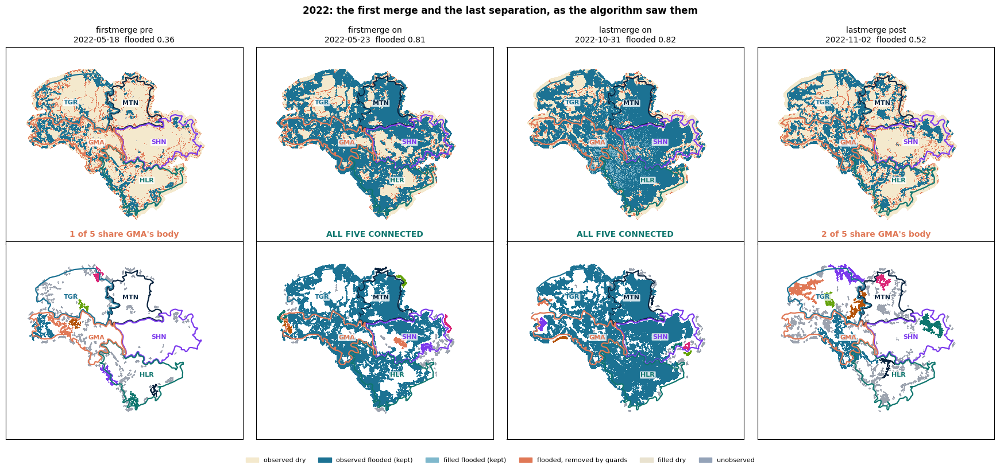

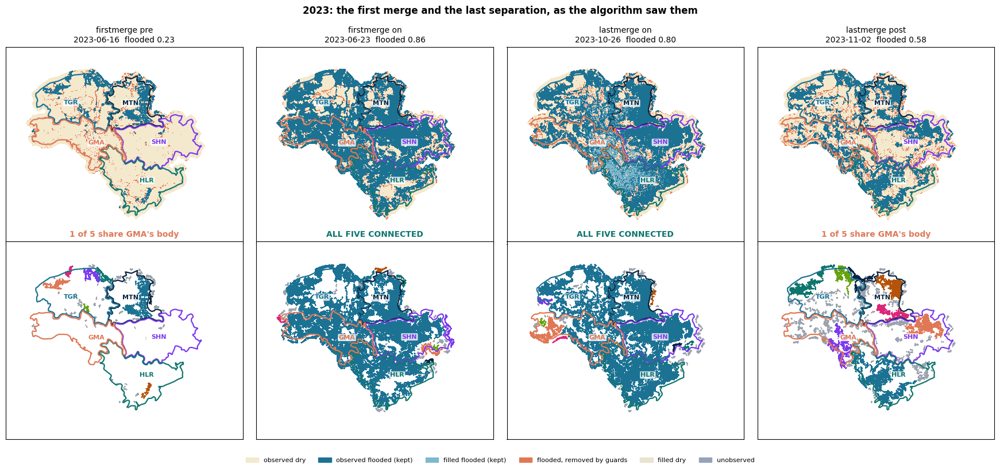

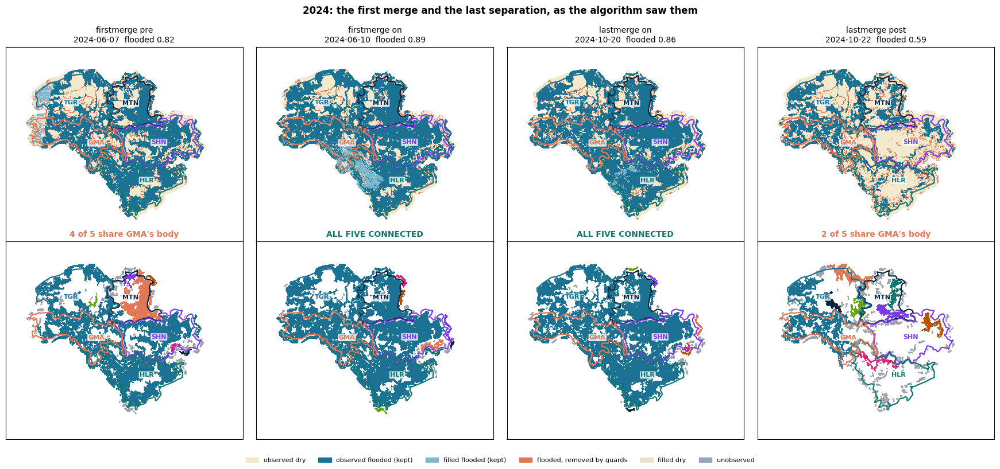

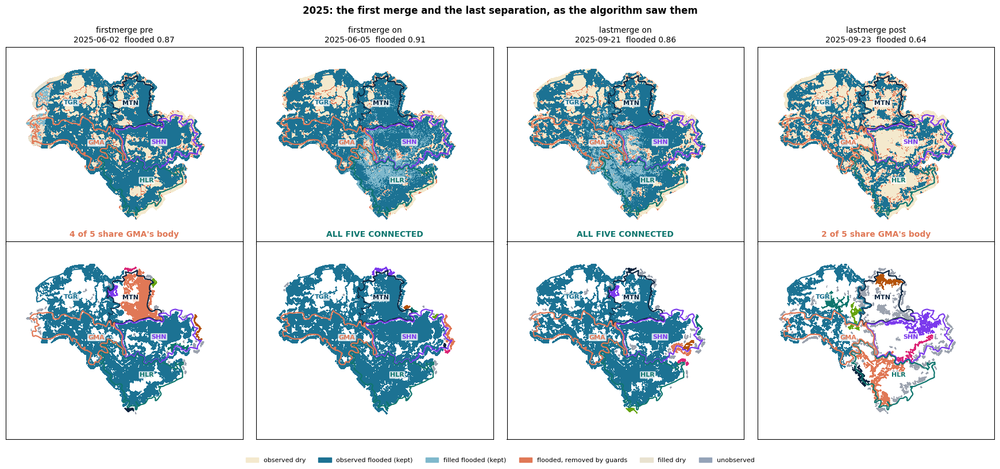

In [5]:
# ============ V2: WHAT THE ALGORITHM SAW, BEFORE / AT / AFTER MERGING ============
# Meeting: "Check the image before merging and after merging. How exactly does it
# look?" This shows the algorithm's own view: which pixels it observed, which it
# FILLED from an earlier pass, which it threw away, and which body each haor got.
# Top row: pixel classes. Bottom row: water bodies, coloured by size rank.
assert have_labels, "run python haor_validation_labels.py on the server first"
for y in YEARS:
    k = KEY[(KEY.year == y) & KEY.role.isin(["firstmerge_pre", "firstmerge_on", "lastmerge_on", "lastmerge_post"])]
    if not len(k):
        print(f"{y}: no merge this year"); continue
    fig, ax = plt.subplots(2, len(k), figsize=(4.4 * len(k), 8.2), squeeze=False)
    for j, (_, r) in enumerate(k.iterrows()):
        code, ext, *_ = read_band(os.path.join(LABELS, f"codes_{y}.tif"), y, r.doy)
        lab, *_ = read_band(os.path.join(LABELS, f"labels_{y}.tif"), y, r.doy)
        ax[0][j].imshow(np.where(code == 255, 6, code), cmap=CODE_CMAP, norm=CODE_NORM, extent=ext, interpolation="nearest")
        ax[1][j].imshow(body_rgb(np.where(lab == core.LABEL_SKIPPED, 0, lab)), extent=ext, interpolation="nearest")
        for a in ax[:, j]:
            draw_haors(a); a.set_xlim(90.93, 91.34); a.set_ylim(24.91, 25.22); a.set_xticks([]); a.set_yticks([])
        ax[0][j].set_title(f"{r.role.replace('_', ' ')}\n{r.date}  flooded {r.cluster_frac:.2f}", fontsize=10)
        ax[1][j].set_title(r.state, fontsize=10, fontweight="bold",
                           color="#0F766E" if "ALL" in r.state else "#E07856")
    fig.legend(handles=CODE_LEGEND, loc="lower center", ncol=6, fontsize=8, frameon=False)
    fig.suptitle(f"{y}: the first merge and the last separation, as the algorithm saw them", fontweight="bold")
    plt.tight_layout(rect=[0, 0.04, 1, 0.97])
    plt.savefig(os.path.join(FIGS, f"V2_transitions_{y}.png"), dpi=170); plt.show()

In [6]:
# ============ V3: TIME-LAPSE OF EVERY SEASON ============
# Meeting (assistant professor): "Make a time-lapse, a movie, like a satellite
# image movie: these are now connected, these are not connected, now they work
# as a whole bowl." One frame per scored date. Left: the water bodies, coloured
# by size rank, with the verdict. Right: the flooded fraction with the 0.80 line
# and the merged dates shaded, and a marker at the current date.
ANIM_YEARS = YEARS                 # set to e.g. [2022, 2024] to save time
FPS = 4
import imageio.v2 as imageio
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
# Frames are drawn outside pyplot and written straight to disk, so memory stays
# flat however many dates and years are animated.
for y in ANIM_YEARS:
    v = conn[y][conn[y]["n_components"] >= 0].sort_values("doy")
    cur = curves[y].sort_values("doy")
    tmp = os.path.join(FIGS, f"_frames_{y}"); os.makedirs(tmp, exist_ok=True)
    pngs = []
    with rasterio.open(os.path.join(LABELS, f"labels_{y}.tif")) as s:
        idx = {core.dayidx(d, y): i + 1 for i, d in enumerate(s.descriptions)}
        ext = plotting_extent(s)
        for k, (_, r) in enumerate(v.iterrows()):
            lab = s.read(idx[r.doy])
            fig = Figure(figsize=(11, 5.2), dpi=90); FigureCanvasAgg(fig)
            a1 = fig.add_axes([0.02, 0.06, 0.48, 0.84]); a2 = fig.add_axes([0.58, 0.18, 0.39, 0.66])
            a1.imshow(body_rgb(lab), extent=ext, interpolation="nearest"); draw_haors(a1, names=True)
            a1.set_xlim(90.93, 91.34); a1.set_ylim(24.91, 25.22); a1.set_xticks([]); a1.set_yticks([])
            st, _ = state_text(y, r.doy)
            a1.set_title(f"{core.doy_to_date(y, r.doy)}   {st}", fontsize=12, fontweight="bold",
                         color="#0F766E" if "ALL" in st else "#334155")
            for _, q in v[v.all_connected].iterrows():
                a2.axvspan(q.doy - 1.5, q.doy + 1.5, color="#1C7293", alpha=.25, lw=0)
            a2.plot(cur.doy, cur.cluster_frac, "o", ms=2.5, color="#0A2540")
            a2.axhline(0.80, color="#E07856", ls="--"); a2.axvline(r.doy, color="k", lw=1.5)
            a2.set_ylim(-0.02, 1.02); a2.set_xlim(85, 460); a2.set_xlabel("days since 1 Jan")
            a2.set_ylabel("mean flooded fraction"); a2.set_title("shaded = all five merged", fontsize=10)
            p = os.path.join(tmp, f"f{k:04d}.png"); fig.savefig(p); pngs.append(p)
            fig.clear(); del fig
    gif = os.path.join(FIGS, f"V3_timelapse_{y}.gif")
    with imageio.get_writer(gif, mode="I", duration=1000 / FPS, loop=0) as w:
        for p in pngs:
            w.append_data(imageio.imread(p)[..., :3])
    msg = f"{y}: {len(pngs)} frames -> {gif}"
    if shutil.which("ffmpeg"):
        mp4 = os.path.join(FIGS, f"V3_timelapse_{y}.mp4")
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-framerate", str(FPS), "-i",
                        os.path.join(tmp, "f%04d.png"), "-vf", "pad=ceil(iw/2)*2:ceil(ih/2)*2",
                        "-pix_fmt", "yuv420p", mp4], check=False)
        msg += f" and {mp4}"
    shutil.rmtree(tmp, ignore_errors=True)
    print(msg)

2019: 111 frames -> /work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/figs/V3_timelapse_2019.gif
2020: 124 frames -> /work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/figs/V3_timelapse_2020.gif
2021: 118 frames -> /work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/figs/V3_timelapse_2021.gif
2022: 116 frames -> /work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/figs/V3_timelapse_2022.gif
2023: 113 frames -> /work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/figs/V3_timelapse_2023.gif
2024: 108 frames -> /work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/figs/V3_timelapse_2024.gif
2025: 116 frames -> /work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/figs/V3_timelapse_2025.gif


Adjacent pairs, all years. direct_share = merged observations whose shared body
crosses THIS pair's own boundary; filled_share = share of crossing pixels that
were not observed that day and came from persistence filling.

   pair  merged_obs  direct_share  crossing_px_median  filled_share  zone_obs_separate  zone_obs_merged
HLR-GMA         213           1.0               385.0         0.056           0.997870         0.944080
SHN-GMA         197           1.0               174.0         0.030           0.999212         0.979249

overall: 100% of merged pair observations cross their own boundary; 4.8% of crossing pixels were filled


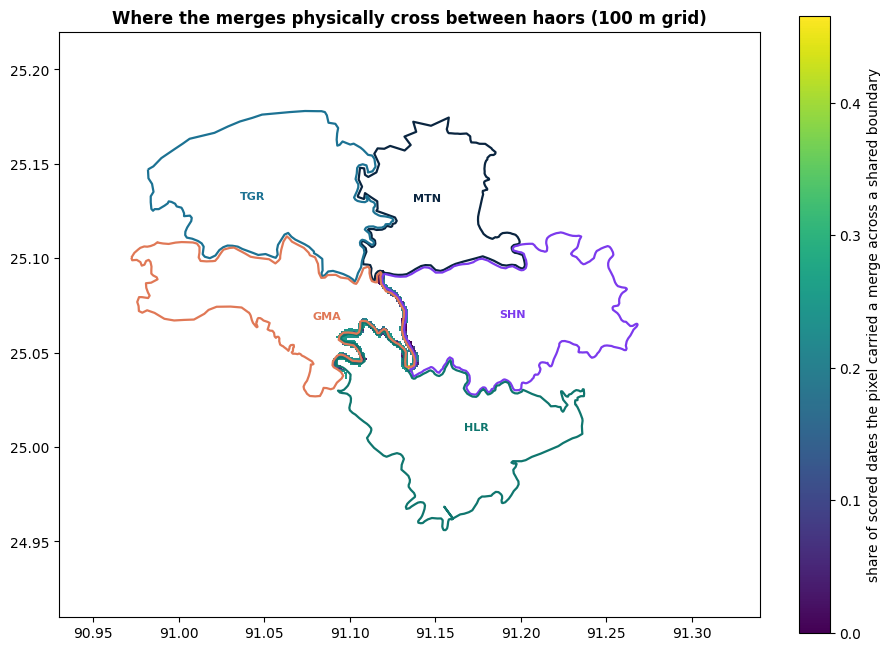

Read this map against the dry season optical image (V5) and against a map of
embankments: crossings concentrated where an embankment runs are the levee problem.


In [12]:
# ============ V4: WHERE DO THE CONNECTIONS CROSS? ============
# Meeting (Prof. Yamazaki): "What is the typical size of the embankment, and the
# pixel size? A levee can be missed: it looks connected, but there could be a
# levee." A merge that is physically real should cross the shared boundary of
# the two haors. This cell maps, over every merged date, how often each pixel
# carried the shared body across a shared boundary, and reports how much of the
# crossing was made of FILLED pixels (unobserved that day).
cs = []
for y in YEARS:
    f = os.path.join(LABELS, f"contacts_{y}.csv")
    if os.path.exists(f):
        cs.append(pd.read_csv(f))
CT = pd.concat(cs, ignore_index=True)
mg = CT[CT.merged]
tab = (mg.groupby("pair").agg(merged_obs=("merged", "size"),
        direct_share=("link", lambda s: round((s == "direct").mean(), 3)),
        crossing_px_median=("crossing_px", "median"),
        filled_share=("crossing_filled_px", "sum")).reset_index())
tab["filled_share"] = (tab["filled_share"] / mg.groupby("pair")["crossing_px"].sum().values).round(3)
zo = CT.groupby(["pair", "merged"])["zone_obs_frac"].mean().unstack()
tab = tab.merge(zo.rename(columns={True: "zone_obs_merged", False: "zone_obs_separate"}).reset_index(), on="pair")
print("Adjacent pairs, all years. direct_share = merged observations whose shared body")
print("crosses THIS pair's own boundary; filled_share = share of crossing pixels that")
print("were not observed that day and came from persistence filling.\n")
print(tab.to_string(index=False))
print(f"\noverall: {100*(mg.link=='direct').mean():.0f}% of merged pair observations cross their own "
      f"boundary; {100*mg.crossing_filled_px.sum()/max(mg.crossing_px.sum(),1):.1f}% of crossing pixels were filled")

# frequency map of crossing pixels
freq, nobs = None, 0
for y in YEARS:
    with rasterio.open(os.path.join(LABELS, f"labels_{y}.tif")) as s:
        idx = {core.dayidx(d, y): i + 1 for i, d in enumerate(s.descriptions)}
        ext = plotting_extent(s); tr, shp, crs = s.transform, (s.height, s.width), s.crs
        if freq is None:
            masks = core.haor_masks(haors, dict(shape=shp, transform=tr, crs=crs))
            zones = core.contact_zones(masks, adj, 3)
            zone_any = np.zeros(shp, bool)
            for z in zones.values(): zone_any |= z
            freq = np.zeros(shp, float)
        m = mats[y].set_index("doy")
        for doy, row in m.iterrows():
            if (row[HAOR_IDS] < 0).any(): continue
            lab = s.read(idx[doy]); nobs += 1
            for pair, z in zones.items():
                a, b = pair.split("-")
                if row[a] > 0 and row[a] == row[b]:
                    freq += ((lab == row[a]) & z)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(np.where(zone_any, freq / max(nobs, 1), np.nan), extent=ext, cmap="viridis", interpolation="nearest")
draw_haors(ax); ax.set_xlim(90.93, 91.34); ax.set_ylim(24.91, 25.22)
plt.colorbar(im, ax=ax, fraction=.04, label="share of scored dates the pixel carried a merge across a shared boundary")
ax.set_title("Where the merges physically cross between haors (100 m grid)", fontweight="bold")
plt.tight_layout(); plt.savefig(os.path.join(FIGS, "V4_crossing_frequency.png"), dpi=170); plt.show()
print("Read this map against the dry season optical image (V5) and against a map of")
print("embankments: crossings concentrated where an embankment runs are the levee problem.")

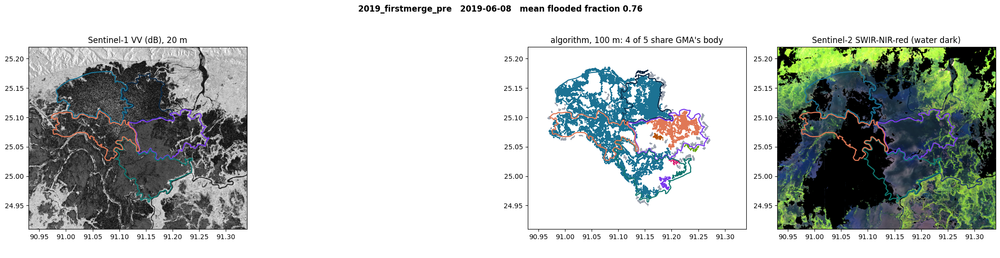

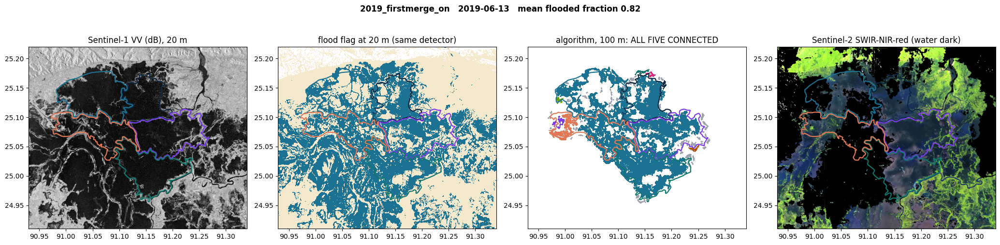

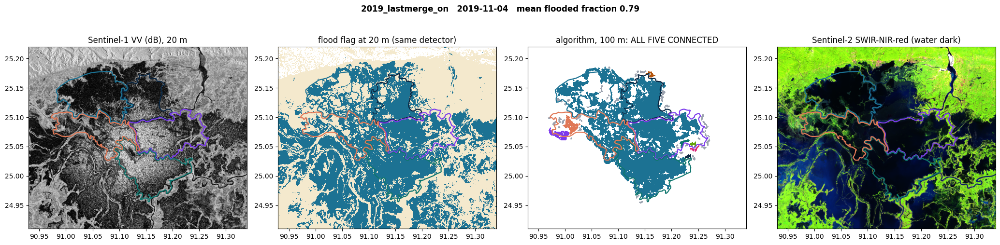

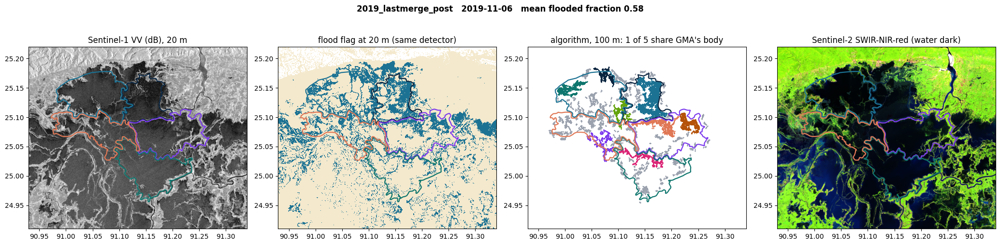

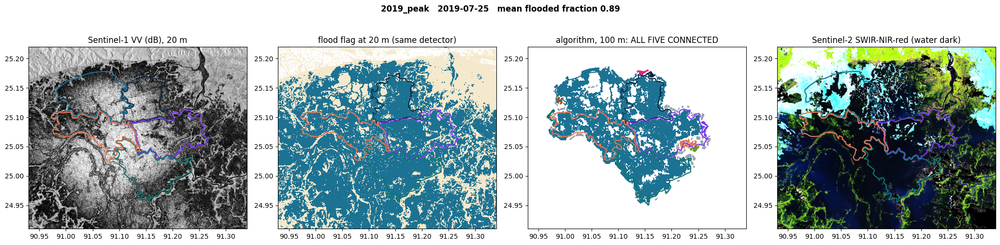

...

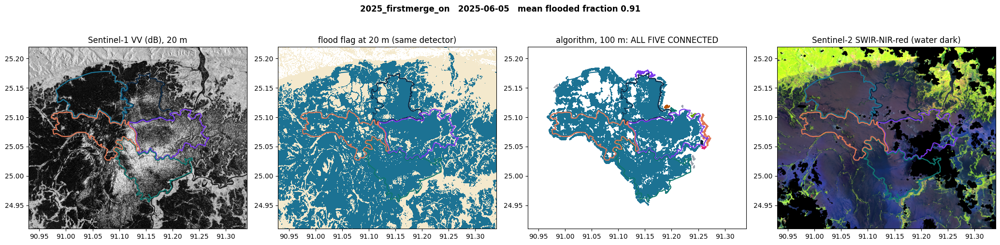

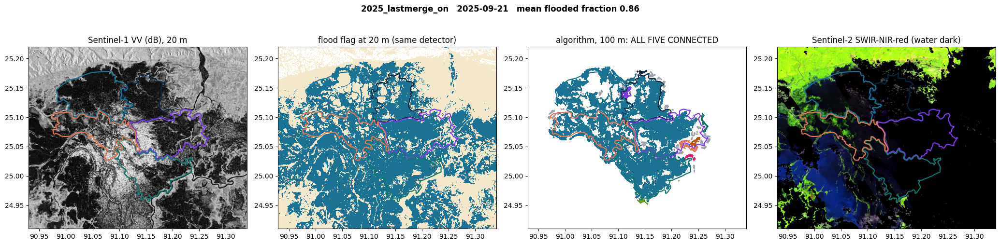

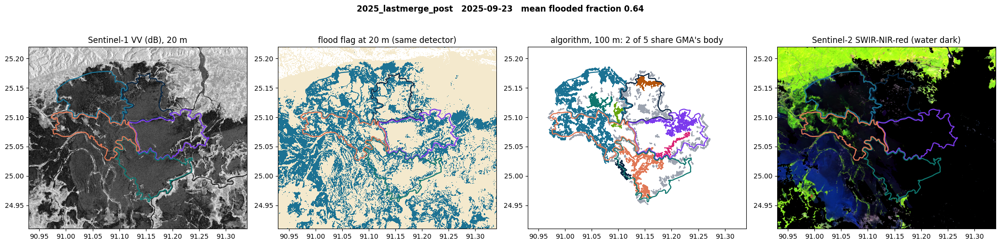

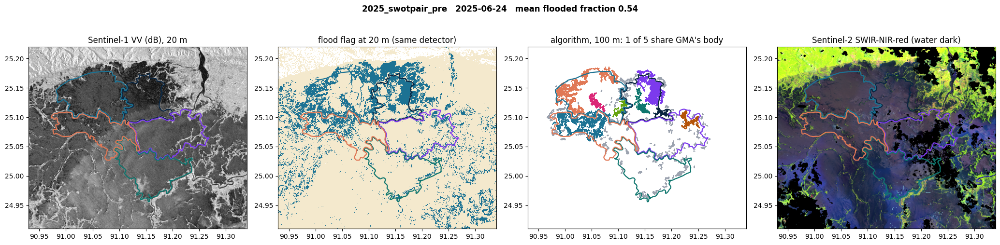

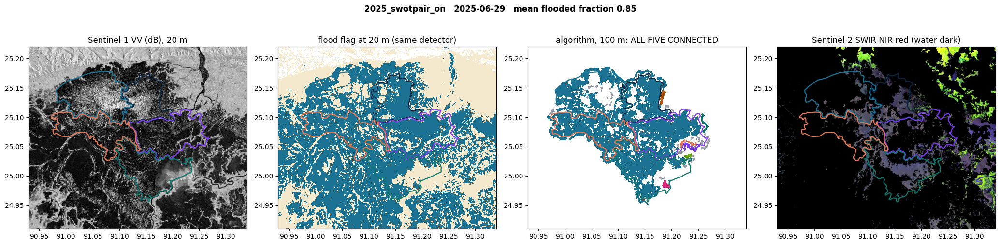

pair states, 100 m against 20 m on the key dates: agreement 80% (n = 86)
20 m merged   False  True 
100 m merged              
False            31      0
True             17     38


In [8]:
# ============ V5: THE REAL IMAGES ON THE KEY DATES ============
# Needs the exports from haor_export_validation_images.py, downloaded to
# validation/images/. For each key date: Sentinel-1 VV backscatter at 20 m
# (the raw measurement, no threshold), the production flood flag at 20 m, the
# algorithm's 100 m bodies, and Sentinel-2 false colour if the sky was clear.
# Then the 20 m flood flag is run through the SAME connectivity code with the
# guards scaled to the same physical size, and the pair states compared with
# the 100 m result. Disagreement on a key date is a direct resolution problem.
def img_path(label, kind, date):
    hits = glob.glob(os.path.join(IMAGES, f"{label}_{kind}_{date.replace('-', '')}*.tif"))
    return hits[0] if hits else None

if not os.path.isdir(IMAGES) or not glob.glob(os.path.join(IMAGES, "*.tif")):
    print(f"no images yet in {IMAGES}. Run haor_export_validation_images.py and download the Drive folder.")
else:
    res_rows = []
    for _, r in KEY.iterrows():
        p1, p2, p3 = img_path(r.label, "S1", r.date), img_path(r.label, "FL20", r.date), img_path(r.label, "S2", r.date)
        if not p1:
            continue
        with rasterio.open(p1) as s:
            vv = s.read(1).astype(float); vv[vv == -32768] = np.nan; vv /= 100; e1 = plotting_extent(s)
        lab, ext, *_ = read_band(os.path.join(LABELS, f"labels_{r.year}.tif"), r.year, r.doy)
        n = 3 + (p3 is not None)
        fig, ax = plt.subplots(1, n, figsize=(5.2 * n, 5.4))
        ax[0].imshow(vv, extent=e1, cmap="gray", vmin=-25, vmax=-2); ax[0].set_title("Sentinel-1 VV (dB), 20 m")
        if p2:
            with rasterio.open(p2) as s:
                fl = s.read(1).astype(float); fl[fl == 255] = np.nan; e2 = plotting_extent(s)
                tr2, crs2 = s.transform, s.crs
            ax[1].imshow(fl, extent=e2, cmap=ListedColormap(["#F4E9CD", "#1C7293"]), vmin=0, vmax=1, interpolation="nearest")
            ax[1].set_title("flood flag at 20 m (same detector)")
            # same connectivity at 20 m, physical guards
            res = 20.0; f = 100 / res
            p20 = dict(core.DEFAULTS, MIN_PX=int(round(10 * f * f)), BUFFER_PX=int(round(800 / res)),
                       BRIDGE=int(np.ceil((300 / res - 1) / 2)))
            m20 = core.haor_masks(haors, dict(shape=fl.shape, transform=tr2, crs=crs2))
            st20 = ndimage.binary_dilation(core.cluster_union(m20), iterations=p20["BUFFER_PX"])
            r20 = core.label_one(fl, m20, st20, 1.0, p20)
            _, row100 = state_text(r.year, r.doy)
            for pair in ADJ:
                a, b = pair.split("-")
                s100 = row100[a] > 0 and row100[a] == row100[b]
                s20 = r20["comp"][a] > 0 and r20["comp"][a] == r20["comp"][b]
                res_rows.append(dict(label=r.label, date=r.date, pair=pair, merged_100m=s100, merged_20m=s20))
        else:
            ax[1].axis("off")
        ax[2].imshow(body_rgb(lab), extent=ext, interpolation="nearest"); ax[2].set_title(f"algorithm, 100 m: {r.state}")
        if p3:
            with rasterio.open(p3) as s:
                b11, b8, b4 = [s.read(i).astype(float) for i in (5, 4, 1)]; e3 = plotting_extent(s)
            rgb = np.dstack([b11, b8, b4]) / 3000.0
            ax[3].imshow(np.clip(rgb, 0, 1), extent=e3); ax[3].set_title("Sentinel-2 SWIR-NIR-red (water dark)")
        for a in ax:
            if a.axison:
                draw_haors(a, names=False); a.set_xlim(90.93, 91.34); a.set_ylim(24.91, 25.22)
        fig.suptitle(f"{r.label}   {r.date}   mean flooded fraction {r.cluster_frac:.2f}", fontweight="bold")
        plt.tight_layout(); plt.savefig(os.path.join(FIGS, f"V5_{r.label}.png"), dpi=150); plt.show(); plt.close(fig)
    if res_rows:
        RR = pd.DataFrame(res_rows); RR.to_csv(os.path.join(VAL, "V5_100m_vs_20m.csv"), index=False)
        agree = (RR.merged_100m == RR.merged_20m).mean()
        print(f"pair states, 100 m against 20 m on the key dates: agreement {100*agree:.0f}% (n = {len(RR)})")
        print(pd.crosstab(RR.merged_100m, RR.merged_20m, rownames=["100 m merged"], colnames=["20 m merged"]))

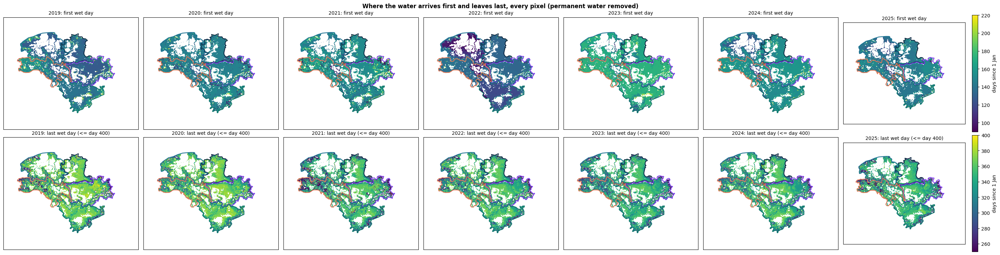

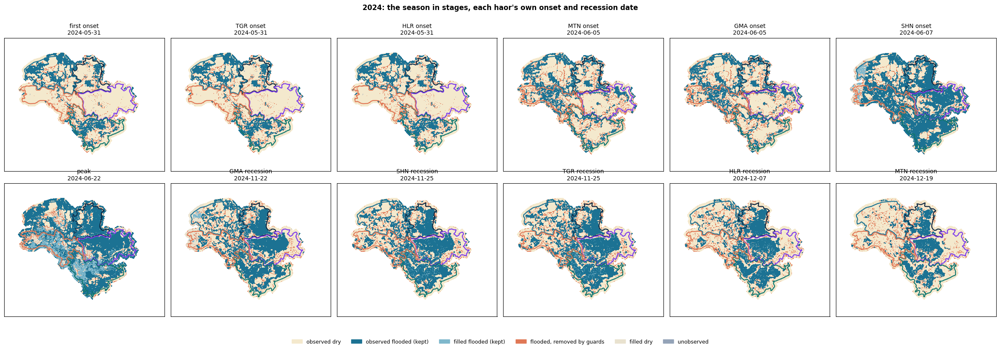

In [9]:
# ============ V6: ONSET AND RECESSION AS 2D MAPS (RQ1) ============
# Meeting (Prof. Yamazaki): "I still don't see the validation for the previous
# results, onset and offset. You only analysed the data; show the original
# image, the actual 2D maps. Guess how water moves at onset: which haor fills
# first, where the water comes from. Onset, peak and offset stages."
# Top: first wet date per pixel (permanent water removed). Bottom: last wet date
# per pixel computed here from the filled stack WITHOUT the February to March
# tail (dates after day 400 ignored), because the exported last_wet_date takes a
# maximum and is corrupted by winter false positives.
fig, ax = plt.subplots(2, len(YEARS), figsize=(4.2 * len(YEARS), 7.6), squeeze=False)
for j, y in enumerate(YEARS):
    with rasterio.open(os.path.join(BASE, f"first_wet_date_{y}.tif")) as s:
        fw = s.read(1).astype(float); ext = plotting_extent(s); tr, crs = s.transform, s.crs
    bands, days, meta = core.read_stack(os.path.join(BASE, f"flood_stack_cluster_{y}.tif"), y)
    if fw.shape != meta["shape"]:
        fw = np.full(meta["shape"], np.nan)
    perm = perm_mask_on(meta["transform"], meta["shape"], meta["crs"])
    filled, _ = core.persistence_fill(bands, days, core.DEFAULTS["MAX_GAP_DAYS"])
    lw = np.full(meta["shape"], np.nan)
    for b, d in zip(filled, days):
        if d <= 400:
            lw[np.isfinite(b) & (b == 1)] = d
    cl = core.cluster_union(core.haor_masks(haors, meta))
    for i, (arr, ttl, vr) in enumerate([(fw, "first wet day", (90, 220)), (lw, "last wet day (<= day 400)", (250, 400))]):
        a = np.where(cl & ~perm & (arr > 0), arr, np.nan)
        im = ax[i][j].imshow(a, extent=plotting_extent(*[None]) if False else ext, cmap="viridis", vmin=vr[0], vmax=vr[1], interpolation="nearest")
        draw_haors(ax[i][j], names=False); ax[i][j].set_xlim(90.93, 91.34); ax[i][j].set_ylim(24.91, 25.22)
        ax[i][j].set_xticks([]); ax[i][j].set_yticks([])
        ax[i][j].set_title(f"{y}: {ttl}", fontsize=10)
        if j == len(YEARS) - 1:
            plt.colorbar(im, ax=ax[i][j], fraction=.046, label="days since 1 Jan")
fig.suptitle("Where the water arrives first and leaves last, every pixel (permanent water removed)", fontweight="bold")
plt.tight_layout(); plt.savefig(os.path.join(FIGS, "V6_onset_offset_maps.png"), dpi=160); plt.show()

# stage snapshots for one year: earliest onset, each haor's onset, peak, each haor's recession
SNAP_YEAR = 2024 if 2024 in YEARS else YEARS[-1]
t = timing[SNAP_YEAR].set_index("haor_id")
stages = [("first onset", t.onset_hydro.min())] + \
         [(f"{h} onset", t.loc[h, "onset_hydro"]) for h in t.sort_values("onset_hydro").index] + \
         [("peak", t.peak_hydro.median())] + \
         [(f"{h} recession", t.loc[h, "recession_hydro"]) for h in t.sort_values("recession_hydro").index]
fig, ax = plt.subplots(2, 6, figsize=(24, 8.4)); ax = ax.ravel()
for a, (nm, doy) in zip(ax, stages[:12]):
    code, ext, *_ = read_band(os.path.join(LABELS, f"codes_{SNAP_YEAR}.tif"), SNAP_YEAR, doy)
    a.imshow(np.where(code == 255, 6, code), cmap=CODE_CMAP, norm=CODE_NORM, extent=ext, interpolation="nearest")
    draw_haors(a, names=False); a.set_xlim(90.93, 91.34); a.set_ylim(24.91, 25.22); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{nm}\n{core.doy_to_date(SNAP_YEAR, doy)}", fontsize=10)
for a in ax[len(stages):]:
    a.axis("off")
fig.legend(handles=CODE_LEGEND, loc="lower center", ncol=6, fontsize=9, frameon=False)
fig.suptitle(f"{SNAP_YEAR}: the season in stages, each haor's own onset and recession date", fontweight="bold")
plt.tight_layout(rect=[0, 0.04, 1, 0.97]); plt.savefig(os.path.join(FIGS, f"V6_stages_{SNAP_YEAR}.png"), dpi=150); plt.show()

In [10]:
# ============ V6b: IS THE RECESSION SPREAD BIGGER THAN ITS OWN UNCERTAINTY? (RQ1) ============
# The Oxford claim "onset stays below the noise floor, recession rises above it
# in all seven years" compares BOTH spreads with onset_within_std, the pixel
# scatter of ONSET dates. Against the pixel scatter of RECESSION dates
# (offset_within_std) the recession spread is smaller in every year. This cell
# prints both, then replaces the pixel-scatter yardstick with two that belong to
# a basin-level date:
#   bracket : days between the last pass at or above 50% and the next pass, i.e.
#             how far the true crossing can sit from the reported date
#   level   : how much the between-basin spread changes when 50% becomes 40% or 60%
# A spread is meaningful only if it is clearly larger than both.
def crossing(doys, fr, lvl, kind):
    m = np.nanmax(fr)
    if not np.isfinite(m) or m <= 0: return np.nan, np.nan
    above = np.where(fr >= lvl * m)[0]
    if not len(above): return np.nan, np.nan
    i = above[0] if kind == "onset" else above[-1]
    j = i - 1 if kind == "onset" else i + 1
    br = abs(doys[i] - doys[j]) if 0 <= j < len(doys) else np.nan
    return float(doys[i]), float(br)
rq = []
for y in YEARS:
    c = curves[y].sort_values("doy"); dd = c.doy.values
    r = dict(year=y)
    for kind in ["onset", "recession"]:
        for lvl in [0.4, 0.5, 0.6]:
            ds = [crossing(dd, c[h].values, lvl, kind)[0] for h in HAOR_IDS]
            r[f"{kind}_spread_{int(lvl*100)}"] = np.nanmax(ds) - np.nanmin(ds)
        r[f"{kind}_bracket"] = np.nanmedian([crossing(dd, c[h].values, 0.5, kind)[1] for h in HAOR_IDS])
    if y in summary.index:
        r["onset_within_std"] = summary.loc[y, "onset_within_std"]
        r["offset_within_std"] = summary.loc[y, "offset_within_std"]
    rq.append(r)
RQ = pd.DataFrame(rq)
RQ["recession_level_range"] = RQ[["recession_spread_40", "recession_spread_50", "recession_spread_60"]].max(axis=1) - \
                              RQ[["recession_spread_40", "recession_spread_50", "recession_spread_60"]].min(axis=1)
RQ["recession_beats_bracket"] = RQ.recession_spread_50 > 2 * RQ.recession_bracket
RQ["onset_beats_bracket"] = RQ.onset_spread_50 > 2 * RQ.onset_bracket
cols = ["year", "onset_spread_50", "onset_bracket", "onset_within_std", "recession_spread_50", "recession_bracket",
        "recession_level_range", "offset_within_std", "onset_beats_bracket", "recession_beats_bracket"]
print(RQ[[c for c in cols if c in RQ]].round(1).to_string(index=False))
RQ.to_csv(os.path.join(VAL, "V6b_rq1_yardsticks.csv"), index=False)
if "offset_within_std" in RQ:
    print(f"\nrecession spread above the ONSET pixel scatter : {int((RQ.recession_spread_50 > RQ.onset_within_std).sum())} of {len(RQ)} years (the slide's comparison)")
    print(f"recession spread above the RECESSION pixel scatter: {int((RQ.recession_spread_50 > RQ.offset_within_std).sum())} of {len(RQ)} years")
print(f"recession spread > 2 x pass bracket            : {int(RQ.recession_beats_bracket.sum())} of {len(RQ)} years")
print(f"onset spread     > 2 x pass bracket            : {int(RQ.onset_beats_bracket.sum())} of {len(RQ)} years")
print("""Pixel scatter measures how varied the floor of ONE basin is, not how well the
basin's date is known, so it is the wrong yardstick for a between-basin spread.
Quote the bracket comparison and Kendall's W (V12) for the drain order instead.""")

 year  onset_spread_50  onset_bracket  onset_within_std  recession_spread_50  recession_bracket  recession_level_range  offset_within_std  onset_beats_bracket  recession_beats_bracket
 2019             24.0            5.0              22.0                 36.0                2.0                    2.0               40.8                 True                     True
 2020              3.0            3.0              18.8                 27.0                2.0                    3.0               38.9                False                     True
 2021              9.0            5.0              22.6                 39.0                2.0                   12.0               49.2                False                     True
 2022             27.0            3.0              18.8                 24.0                2.0                   12.0               41.5                 True                     True
 2023              7.0            7.0              15.6                 34.0    

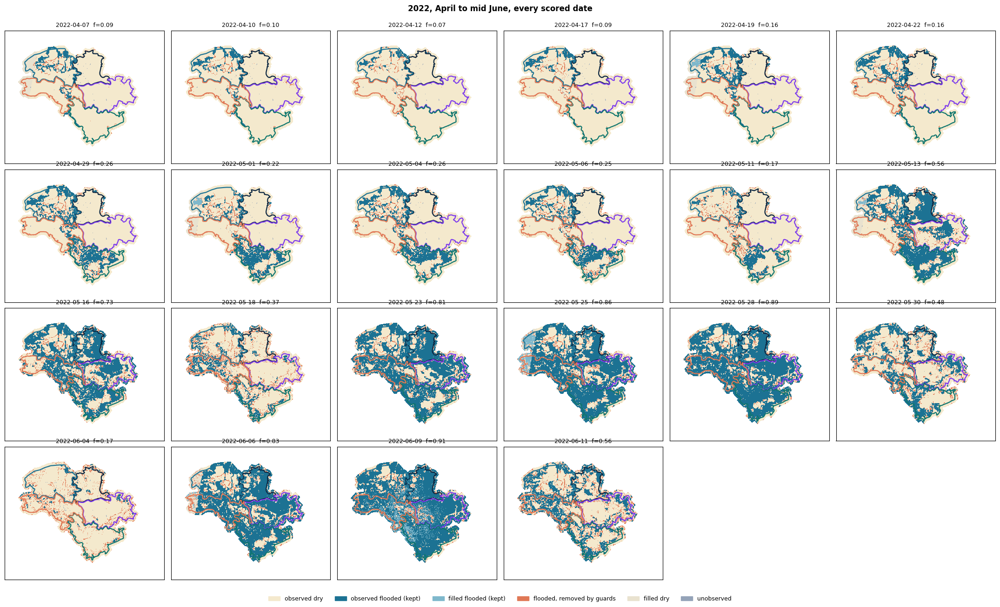

Flooded fraction and the share of that water lying within 300 m of a permanent beel,
mean over days 95 to 140 of 2022 (the early window):

       frac  share_near_beel
haor                        
GMA   0.164            0.766
HLR   0.353            0.536
MTN   0.146            0.648
SHN   0.083            0.281
TGR   0.519            0.647

If TGR's early water sits mostly next to its beels while the others' does not,
the 'Tanguar rose first' result is beel expansion, not a separate early flood.
Then check the April 2022 images in V5 (labels 2022_event1 to 2022_event5).


In [11]:
# ============ V7: 2022, THE FLASH FLOOD AS A CASE STUDY ============
# Meeting (assistant professor): "2022 was a huge flood. Can you use that as a
# validation period: snapshots before the extreme event, and during it?"
# The Oxford claim was that Tanguar alone rose in mid April 2022. Tanguar also
# holds the most permanent water (43% of its pixels masked). An early rise that
# sits only on the edges of the permanent beels would be beel expansion or a
# masking effect, not an early flood. This cell maps every date and measures it.
EV = 2022
if EV in YEARS:
    v = conn[EV][(conn[EV].n_components >= 0) & (conn[EV].doy.between(95, 165))].sort_values("doy")
    n = len(v); ncol = 6; nrow = int(np.ceil(n / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.3 * nrow), squeeze=False); ax = ax.ravel()
    for a, (_, r) in zip(ax, v.iterrows()):
        code, ext, *_ = read_band(os.path.join(LABELS, f"codes_{EV}.tif"), EV, r.doy)
        a.imshow(np.where(code == 255, 6, code), cmap=CODE_CMAP, norm=CODE_NORM, extent=ext, interpolation="nearest")
        draw_haors(a, names=False); a.set_xlim(90.93, 91.34); a.set_ylim(24.91, 25.22); a.set_xticks([]); a.set_yticks([])
        a.set_title(f"{core.doy_to_date(EV, r.doy)}  f={frac_at(EV, r.doy):.2f}", fontsize=9)
    for a in ax[n:]:
        a.axis("off")
    fig.legend(handles=CODE_LEGEND, loc="lower center", ncol=6, fontsize=9, frameon=False)
    fig.suptitle("2022, April to mid June, every scored date", fontweight="bold")
    plt.tight_layout(rect=[0, 0.03, 1, 0.98]); plt.savefig(os.path.join(FIGS, "V7_2022_sequence.png"), dpi=140); plt.show()

    # where is the early water? distance from permanent water, per haor
    bands, days, meta = core.read_stack(os.path.join(BASE, f"flood_stack_cluster_{EV}.tif"), EV)
    masks = core.haor_masks(haors, meta)
    perm = perm_mask_on(meta["transform"], meta["shape"], meta["crs"])
    near = ndimage.binary_dilation(perm, iterations=3) & ~perm          # within 300 m of a beel
    rows = []
    for b, d in zip(bands, days):
        if not (95 <= d <= 140):
            continue
        for h, m in masks.items():
            sel = m & ~perm & np.isfinite(b)
            wet = sel & (b == 1)
            if sel.sum() == 0: continue
            rows.append(dict(doy=d, haor=h, frac=wet.sum() / sel.sum(),
                             share_near_beel=(wet & near).sum() / max(wet.sum(), 1)))
    E = pd.DataFrame(rows)
    print("Flooded fraction and the share of that water lying within 300 m of a permanent beel,")
    print("mean over days 95 to 140 of 2022 (the early window):\n")
    print(E.groupby("haor")[["frac", "share_near_beel"]].mean().round(3).to_string())
    print("\nIf TGR's early water sits mostly next to its beels while the others' does not,")
    print("the 'Tanguar rose first' result is beel expansion, not a separate early flood.")
    print("Then check the April 2022 images in V5 (labels 2022_event1 to 2022_event5).")

In [14]:
# ============ V8: A BLIND REFERENCE SET, LABELLED BY EYE ============
# Meeting (assistant professor): "For your case there is no reference. You need
# to create the reference yourself." This makes one. For every key date with an
# exported Sentinel-1 image it draws a card showing ONLY the 20 m backscatter and
# the haor outlines: no flood flag, no algorithm result, coded ID instead of the
# date. You judge each adjacent pair by eye as connected (C), separate (S) or
# unclear (U) in reference_labels.csv. V9 then compares your eye with the
# algorithm. Do not open key_ids.csv until you have finished labelling.
CARDS = os.path.join(VAL, "reference_cards"); os.makedirs(CARDS, exist_ok=True)
avail = [r for _, r in KEY.iterrows() if img_path(r.label, "S1", r.date)]
if not avail:
    print("no Sentinel-1 images downloaded yet; run V5's export first")
else:
    rng = np.random.default_rng(20261001)
    ids = rng.permutation(len(avail))
    keymap, tmpl = [], []
    for card, r in zip(ids, avail):
        cid = f"card{card:03d}"
        with rasterio.open(img_path(r.label, "S1", r.date)) as s:
            vv = s.read(1).astype(float); vv[vv == -32768] = np.nan; vv /= 100; e1 = plotting_extent(s)
        fig, ax = plt.subplots(figsize=(9, 7.5))
        ax.imshow(vv, extent=e1, cmap="gray", vmin=-25, vmax=-2); draw_haors(ax)
        ax.set_xlim(90.93, 91.34); ax.set_ylim(24.91, 25.22); ax.set_title(cid, fontweight="bold")
        plt.tight_layout(); plt.savefig(os.path.join(CARDS, f"{cid}.png"), dpi=150); plt.close(fig)
        keymap.append(dict(card=cid, label=r.label, year=r.year, doy=r.doy, date=r.date))
        for pair in ADJ:
            tmpl.append(dict(card=cid, pair=pair, your_label=""))
    pd.DataFrame(keymap).to_csv(os.path.join(VAL, "reference_key_ids.csv"), index=False)
    out = os.path.join(VAL, "reference_labels.csv")
    if not os.path.exists(out):
        pd.DataFrame(tmpl).sort_values(["card", "pair"]).to_csv(out, index=False)
        print(f"wrote {len(avail)} cards to {CARDS} and the blank sheet {out}")
    else:
        print(f"{out} already exists, not overwritten (your labels are safe)")
    print("Fill your_label with C, S or U for every row, using only the card image.")

/work/a06/wasif/haor_flood_analysis_hydroyear/analysis/validation/reference_labels.csv already exists, not overwritten (your labels are safe)
Fill your_label with C, S or U for every row, using only the card image.


In [7]:
# ============ V9: YOUR EYE AGAINST THE ALGORITHM ============
KAPPA = None
lab_file = os.path.join(VAL, "reference_labels.csv")
key_file = os.path.join(VAL, "reference_key_ids.csv")
if os.path.exists(lab_file) and os.path.exists(key_file):
    L = pd.read_csv(lab_file).merge(pd.read_csv(key_file), on="card")
    L = L[L.your_label.astype(str).str.upper().isin(["C", "S"])]
    if not len(L):
        print("no C or S labels filled in yet")
    else:
        alg = []
        for _, r in L.iterrows():
            _, row = state_text(int(r.year), float(r.doy))
            a, b = r.pair.split("-")
            alg.append(bool(row[a] > 0 and row[a] == row[b]))
        L["algorithm"] = np.where(alg, "C", "S"); L["eye"] = L.your_label.str.upper()
        ct = pd.crosstab(L.eye, L.algorithm, rownames=["your eye"], colnames=["algorithm"])
        po = (L.eye == L.algorithm).mean()
        pe = sum((L.eye == k).mean() * (L.algorithm == k).mean() for k in ["C", "S"])
        kappa = (po - pe) / (1 - pe) if pe < 1 else np.nan
        KAPPA = (kappa, len(L))
        print(ct.to_string()); print(f"\nagreement {100*po:.0f}%   Cohen's kappa {kappa:.2f}   n = {len(L)}")
        print(L.groupby("pair").apply(lambda g: round((g.eye == g.algorithm).mean(), 2)).rename("agreement").to_string())
        print("\nkappa above 0.6 is substantial agreement; below 0.4 the algorithm and the image disagree.")
else:
    print("label the cards first (V8)")

algorithm   C   S
your eye         
C          37  26
S          18   6

agreement 49%   Cohen's kappa -0.15   n = 87
pair
HLR-GMA    0.50
SHN-GMA    0.49

kappa above 0.6 is substantial agreement; below 0.4 the algorithm and the image disagree.


In [8]:
# ============ V10: DOES CONNECTIVITY SURVIVE FINER PIXELS? ============
# Needs: haor_export_flood_stack_hires.py (SCALE = 30) then
#        python haor_validation_labels.py --stack-dir /work/a06/wasif/haor_flood_pooled_30m --res 30
hi_dirs = sorted(glob.glob(os.path.join(VAL, "labels_hires_*")))
HIRES_SPLIT = {}
if not hi_dirs:
    print("no high resolution labels yet")
for hd in hi_dirs:
    tag = os.path.basename(hd)
    rows = []
    for y in YEARS:
        f = os.path.join(hd, f"connectivity_recomputed_{y}.csv")
        if not os.path.exists(f): continue
        hi = pd.read_csv(f); lo = conn[y]
        hm = pd.read_csv(os.path.join(hd, f"matrix_recomputed_{y}.csv")).set_index("doy")
        lm = mats[y].set_index("doy")
        common = sorted(set(hi.doy) & set(lo.doy))
        for d in common:
            if (lm.loc[d, HAOR_IDS] < 0).any() or (hm.loc[d, HAOR_IDS] < 0).any(): continue
            for pair in ADJ:
                a, b = pair.split("-")
                rows.append(dict(year=y, doy=d, pair=pair,
                                 lo=bool(lm.loc[d, a] > 0 and lm.loc[d, a] == lm.loc[d, b]),
                                 hi=bool(hm.loc[d, a] > 0 and hm.loc[d, a] == hm.loc[d, b])))
    if not rows:
        print(f"{tag}: nothing comparable"); continue
    R = pd.DataFrame(rows)
    print(f"\n=== {tag} against 100 m, adjacent pairs ===")
    print(pd.crosstab(R.lo, R.hi, rownames=["100 m merged"], colnames=["fine merged"]))
    HIRES_SPLIT[tag] = ((R.lo) & (~R.hi)).sum() / max(R.lo.sum(), 1)
    R.to_csv(os.path.join(VAL, f"V10_{tag}_vs_100m.csv"), index=False)
    print(f"agreement {100*(R.lo == R.hi).mean():.1f}%  |  merged at 100 m but separate when finer: "
          f"{100*((R.lo) & (~R.hi)).sum()/max(R.lo.sum(),1):.1f}% of 100 m merges")
    print(R.groupby("pair").apply(lambda g: pd.Series(dict(merged_100m=g.lo.mean(), merged_fine=g.hi.mean()))).round(3).to_string())
    print("A large 'merged at 100 m but separate when finer' share is the levee problem in numbers.")


=== labels_hires_haor_flood_by_pass_100m_physical against 100 m, adjacent pairs ===
fine merged   False  True 
100 m merged              
False          1179     23
True             10    400
agreement 98.0%  |  merged at 100 m but separate when finer: 2.4% of 100 m merges
         merged_100m  merged_fine
pair                             
HLR-GMA        0.264        0.272
SHN-GMA        0.244        0.253
A large 'merged at 100 m but separate when finer' share is the levee problem in numbers.

=== labels_hires_haor_flood_pooled_30m_physical against 100 m, adjacent pairs ===
fine merged   False  True 
100 m merged              
False           519      0
True            145     10
agreement 78.5%  |  merged at 100 m but separate when finer: 93.5% of 100 m merges
         merged_100m  merged_fine
pair                             
HLR-GMA        0.243        0.024
SHN-GMA        0.217        0.006
A large 'merged at 100 m but separate when finer' share is the levee problem in numbers.


                  run  n_merged  n_merged_change_pct  ws_merge_frac  episodes  thr_median  bal_median  min_frac  window_min  window_max
             baseline       108                  0.0          0.228        75       0.810       0.912     0.673       142.0       314.0
          BUFFER_PX=0       129                 19.4          0.273        81       0.790       0.935     0.665       142.0       314.0
          BUFFER_PX=3       105                 -2.8          0.222        72       0.810       0.912     0.722       142.0       311.0
          BUFFER_PX=5       107                 -0.9          0.226        73       0.810       0.912     0.722       142.0       314.0
         BUFFER_PX=10       112                  3.7          0.237        77       0.810       0.911     0.673       142.0       314.0
         BUFFER_PX=15       128                 18.5          0.271        82       0.790       0.935     0.665       142.0       314.0
             BRIDGE=0       224                1

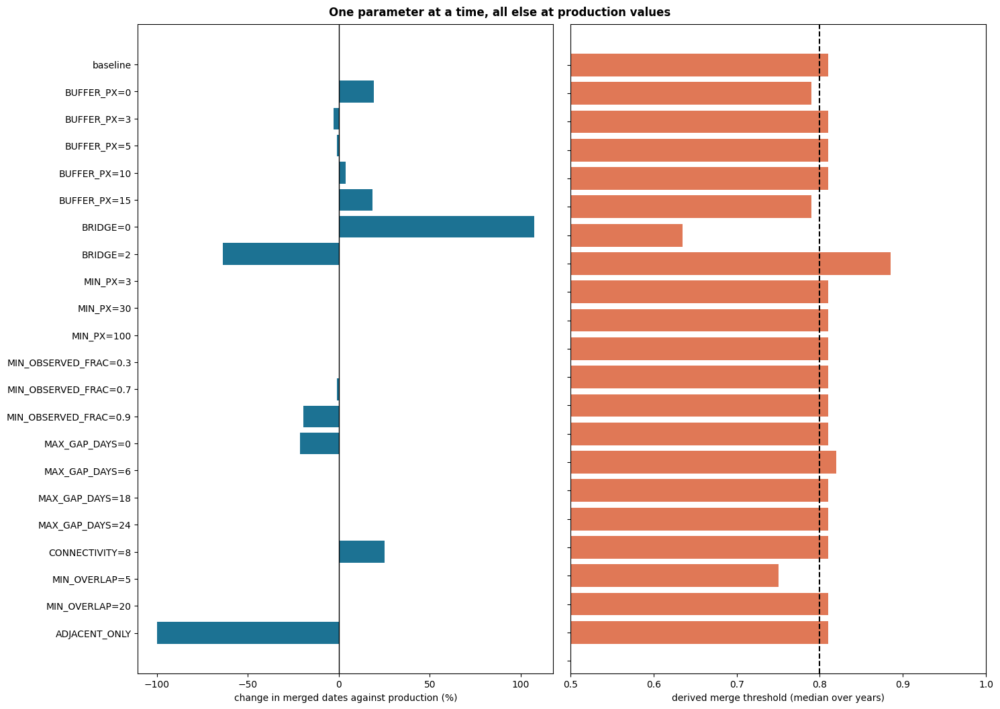

In [14]:
# ============ V11: PARAMETER SENSITIVITY ============
# Meeting (assistant professor): "If anyone asks what happens with 500 m instead
# of 800 m, you can at least report it." From haor_parameter_sensitivity.py.
SD = os.path.join(VAL, "sensitivity", "sensitivity_pooled.csv")
if os.path.exists(SD):
    S = pd.read_csv(SD)
    print(S[["run", "n_merged", "n_merged_change_pct", "ws_merge_frac", "episodes", "thr_median",
             "bal_median", "min_frac", "window_min", "window_max"]].to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(15, 0.42 * len(S) + 1.5))
    yy = np.arange(len(S))
    ax[0].barh(yy, S.n_merged_change_pct, color=np.where(S.run == "baseline", "#0A2540", "#1C7293"))
    ax[0].axvline(0, color="k", lw=1); ax[0].set_yticks(yy); ax[0].set_yticklabels(S.run)
    ax[0].set_xlabel("change in merged dates against production (%)"); ax[0].invert_yaxis()
    ax[1].barh(yy, S.thr_median, color="#E07856"); ax[1].axvline(0.80, color="k", ls="--")
    ax[1].set_yticks(yy); ax[1].set_yticklabels([]); ax[1].invert_yaxis()
    ax[1].set_xlabel("derived merge threshold (median over years)"); ax[1].set_xlim(0.5, 1.0)
    fig.suptitle("One parameter at a time, all else at production values", fontweight="bold")
    plt.tight_layout(); plt.savefig(os.path.join(FIGS, "V11_sensitivity.png"), dpi=160); plt.show()
else:
    print("run python haor_parameter_sensitivity.py first")

In [10]:
# ============ V12: STATISTICS WITHOUT PSEUDO-REPLICATION ============
# The published p values treat every date as independent (A2: p = 1.8e-57 over
# 806 dates) and every haor PAIR on a date as independent (Part B: 868 pairs from
# 87 dates). Consecutive dates are not independent and the ten pairs on one date
# share one SWOT pass. Here the same comparisons are made with one value per
# merge EPISODE and per non-merged RUN, and Kendall's W gets an exact
# permutation p value (the chi-square approximation is poor for 5 basins).
ep_rows = []
for y in YEARS:
    v = conn[y][conn[y].n_components >= 0].sort_values("doy").copy()
    v["frac"] = [frac_at(y, d) for d in v.doy]
    v["run"] = (v.all_connected != v.all_connected.shift()).cumsum()
    for _, g in v.groupby("run"):
        ep_rows.append(dict(year=y, merged=bool(g.all_connected.iloc[0]), n=len(g), frac=g.frac.mean()))
EP = pd.DataFrame(ep_rows)
a, b = EP[EP.merged].frac, EP[~EP.merged].frac
u, pv = mannwhitneyu(a, b, alternative="greater") if len(a) > 2 and len(b) > 2 else (np.nan, np.nan)
print(f"one value per run: merged runs {len(a)} (median fraction {a.median():.3f}), "
      f"other runs {len(b)} (median {b.median():.3f}), Mann-Whitney p = {pv:.2e}")
print("Quote this p value, not 1.8e-57: it counts independent episodes, not dates.\n")

rec = pd.DataFrame({y: timing[y].set_index("haor_id")["recession_hydro"] for y in YEARS})
def W_of(M):
    R = M.rank(axis=0).sum(axis=1); n, m = M.shape
    return 12 * ((R - R.mean()) ** 2).sum() / (m ** 2 * (n ** 3 - n))
W0 = W_of(rec); rng = np.random.default_rng(0)
perm = [W_of(rec.apply(lambda c: pd.Series(rng.permutation(c.values), index=c.index))) for _ in range(20000)]
print(f"Kendall's W (hydrograph recession) = {W0:.3f}, exact permutation p = "
      f"{(np.sum(np.array(perm) >= W0) + 1) / (len(perm) + 1):.1e} (20,000 permutations)")
print("Ties: recession dates fall on satellite passes, so ties also occur in this measure.")
for y in YEARS:
    r = rec[y]; dup = r[r.duplicated(keep=False)]
    if len(dup): print(f"   {y}: tied recession dates for {list(dup.index)}")

# ---- hysteresis (Oxford appendix: 0.81 to connect, 0.74 to stay connected) ----
# The published gap is one number from pooled dates with no interval. Here each
# limb's threshold is found per year, and the pooled gap gets an interval from
# resampling whole YEARS. Both the raw-accuracy threshold (as published) and the
# balanced-accuracy threshold are shown: raw accuracy on a limb with few merged
# dates drifts upward.
def limb_thr(fm, fo, balanced):
    fm, fo = np.asarray(fm), np.asarray(fo)
    if len(fm) < 3 or len(fo) < 3: return np.nan
    grid = np.linspace(0.05, 0.95, 181)
    sc = [(((fm >= t).mean() + (fo < t).mean()) / 2) if balanced else
          (((fm >= t).sum() + (fo < t).sum()) / (len(fm) + len(fo))) for t in grid]
    return float(grid[int(np.argmax(sc))])
LIMB = {}
for y in YEARS:
    v = conn[y][conn[y].n_components >= 0].copy()
    v["frac"] = [frac_at(y, d) for d in v.doy]
    pk = float(v.loc[v.frac.idxmax(), "doy"])
    v["limb"] = np.where(v.doy <= pk, "rising", "falling")
    LIMB[y] = v
hy_rows = []
for y in YEARS:
    v = LIMB[y]; r = dict(year=y)
    for lb in ["rising", "falling"]:
        g = v[v.limb == lb]
        r[f"n_merged_{lb}"] = int(g.all_connected.sum())
        r[f"thr_{lb}"] = limb_thr(g.frac[g.all_connected], g.frac[~g.all_connected], False)
        r[f"bal_thr_{lb}"] = limb_thr(g.frac[g.all_connected], g.frac[~g.all_connected], True)
    hy_rows.append(r)
HY = pd.DataFrame(hy_rows); HY["gap"] = HY.thr_rising - HY.thr_falling; HY["bal_gap"] = HY.bal_thr_rising - HY.bal_thr_falling
print("\nhysteresis per year (threshold to connect on the rising limb minus to stay connected on the falling limb):")
print(HY.round(3).to_string(index=False))
def pooled_gap(ys, balanced):
    v = pd.concat([LIMB[y] for y in ys])
    t = {lb: limb_thr(v.frac[(v.limb == lb) & v.all_connected], v.frac[(v.limb == lb) & ~v.all_connected], balanced)
         for lb in ["rising", "falling"]}
    return t["rising"] - t["falling"]
rng = np.random.default_rng(5); HYST = {}
for bal in [False, True]:
    g0 = pooled_gap(YEARS, bal)
    bs = [pooled_gap(list(rng.choice(YEARS, len(YEARS))), bal) for _ in range(1000)]
    lo, hi = np.nanpercentile(bs, [2.5, 97.5]); HYST["balanced" if bal else "raw"] = (g0, lo, hi)
    print(f"pooled gap ({'balanced' if bal else 'raw accuracy, as published'}): {g0:+.3f}, "
          f"95% year-bootstrap [{lo:+.3f}, {hi:+.3f}]  years with a positive gap: "
          f"{int((HY['bal_gap' if bal else 'gap'] > 0).sum())} of {HY['bal_gap' if bal else 'gap'].notna().sum()}")
HY.to_csv(os.path.join(VAL, "V12_hysteresis_by_year.csv"), index=False)
print("Hysteresis is supported only if the interval excludes 0 AND most years show a positive gap.")
print("Rising limbs hold few dates (the peak comes early), so expect wide intervals.")

one value per run: merged runs 75 (median fraction 0.849), other runs 82 (median 0.561), Mann-Whitney p = 3.13e-26
Quote this p value, not 1.8e-57: it counts independent episodes, not dates.

Kendall's W (hydrograph recession) = 0.909, exact permutation p = 5.0e-05 (20,000 permutations)
Ties: recession dates fall on satellite passes, so ties also occur in this measure.
   2019: tied recession dates for ['TGR', 'GMA']
   2020: tied recession dates for ['SHN', 'HLR']
   2021: tied recession dates for ['SHN', 'HLR']
   2022: tied recession dates for ['SHN', 'HLR', 'TGR', 'GMA']
   2023: tied recession dates for ['SHN', 'HLR']
   2024: tied recession dates for ['SHN', 'TGR']
   2025: tied recession dates for ['SHN', 'HLR']

hysteresis per year (threshold to connect on the rising limb minus to stay connected on the falling limb):
 year  n_merged_rising  thr_rising  bal_thr_rising  n_merged_falling  thr_falling  bal_thr_falling    gap  bal_gap
 2019                3       0.820           0.8

In [15]:
# ============ V13: THE SCORECARD ============
# Each check states in advance what result would count as support. PENDING
# means the input does not exist yet.
def exists(p): return os.path.exists(p)
card = []
card.append(("labels reproduce published output", "check_<Y>.txt says IDENTICAL for every year",
             "PASS" if have_labels and all("IDENTICAL" in open(os.path.join(LABELS, f"check_{y}.txt")).read() for y in YEARS) else "PENDING/FAIL"))
if len(CT):
    ds = (CT[CT.merged].link == "direct").mean()
    fs = CT[CT.merged].crossing_filled_px.sum() / max(CT[CT.merged].crossing_px.sum(), 1)
    card.append(("merges cross their own shared boundary", ">= 90% of merged adjacent-pair observations",
                 f"{'PASS' if ds >= .9 else 'FAIL'} ({100*ds:.0f}%)"))
    card.append(("filled pixels do not build the links", "< 10% of crossing pixels were filled",
                 f"{'PASS' if fs < .1 else 'FAIL'} ({100*fs:.1f}%)"))
rr = os.path.join(VAL, "V5_100m_vs_20m.csv")
if exists(rr):
    RR = pd.read_csv(rr); ag = (RR.merged_100m == RR.merged_20m).mean()
    card.append(("same pair states at 20 m on key dates", ">= 85% agreement", f"{'PASS' if ag >= .85 else 'FAIL'} ({100*ag:.0f}%)"))
else:
    card.append(("same pair states at 20 m on key dates", ">= 85% agreement", "PENDING (V5)"))
if KAPPA is not None:
    card.append(("eye agrees with algorithm (blind)", "Cohen's kappa >= 0.6",
                 f"{'PASS' if KAPPA[0] >= .6 else 'FAIL'} (kappa {KAPPA[0]:.2f}, n {KAPPA[1]})"))
else:
    card.append(("eye agrees with algorithm (blind)", "Cohen's kappa >= 0.6", "PENDING (label the V8 cards)"))
for tag, share in HIRES_SPLIT.items():
    card.append((f"connectivity survives finer pixels ({tag})", "< 20% of 100 m merges become separate",
                 f"{'PASS' if share < .2 else 'FAIL'} ({100*share:.1f}%)"))
if not HIRES_SPLIT:
    card.append(("connectivity survives 30 m pixels", "< 20% of 100 m merges become separate", "PENDING (V10)"))
if exists(SD):
    S = pd.read_csv(SD)
    worst = S.loc[S.run != "baseline", "n_merged_change_pct"].abs().max()
    card.append(("headline stable under one-at-a-time changes", "no single change moves merged dates by > 30%",
                 f"{'PASS' if worst <= 30 else 'FAIL'} (largest {worst:.0f}%)"))
if "RQ" in globals() and len(RQ):
    k = int(RQ.recession_beats_bracket.sum())
    card.append(("RQ1 recession spread is real", "recession spread > 2 x pass bracket in >= 70% of years (5 of 7)",
                 f"{'PASS' if k >= 0.7 * len(RQ) else 'FAIL'} ({k} of {len(RQ)} years)"))
if "HYST" in globals() and "balanced" in HYST:
    g0, lo, hi = HYST["balanced"]
    card.append(("hysteresis (connect above stay-connected)", "year-bootstrap 95% interval of the gap excludes 0",
                 f"{'PASS' if lo > 0 else 'NOT SHOWN'} ({g0:+.3f}, [{lo:+.3f}, {hi:+.3f}])"))
sw = os.path.join(VAL, "scorecard_swot.csv")
if exists(sw):
    for _, r in pd.read_csv(sw).iterrows():
        card.append((f"SWOT: {r['check']}", r["criterion"], r["result"]))
else:
    card.append(("SWOT step test", "run haor_swot_validation.ipynb", "PENDING"))
SC = pd.DataFrame(card, columns=["check", "criterion", "result"])
print(SC.to_string(index=False))
SC.to_csv(os.path.join(VAL, "scorecard_radar.csv"), index=False)

                                                                             check                                                                                                          criterion                                                                  result
                                                 labels reproduce published output                                                                        check_<Y>.txt says IDENTICAL for every year                                                                    PASS
                                            merges cross their own shared boundary                                                                        >= 90% of merged adjacent-pair observations                                                             PASS (100%)
                                              filled pixels do not build the links                                                                               < 10% of crossing pixels were